In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import make_scorer, roc_curve, auc
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from statsmodels.tsa.arima.model import ARIMA

In [14]:
# when you download the data it is in a folder, here are the paths, run this in the same directory as your data folder
train_path = os.path.join('drw-crypto-market-prediction', 'train.parquet')
test_path = os.path.join('drw-crypto-market-prediction', 'test.parquet')
submission_path = os.path.join('drw-crypto-market-prediction', 'sample_submission.csv')

In [15]:
# make scorer, reduce memory use, and engineer relevant features
def pearson_r(true, pred):
    y_true = true - true.mean()
    y_pred = pred - pred.mean()
    bottom = np.sqrt((y_true**2).sum()) * np.sqrt((y_pred**2).sum())
    return 0.0 if bottom == 0 else float((y_pred * y_true).sum() / bottom)

correlation_scorer = make_scorer(pearson_r, greater_is_better=True)

def reduce_memory_use(df):
    for column in df.columns:
        if pd.api.types.is_float_dtype(df[column]):
            df[column] = pd.to_numeric(df[column], downcast='float')
        elif pd.api.types.is_integer_dtype(df[column]):
            df[column] = pd.to_numeric(df[column], downcast='integer')
    return df

def add_features(df):
    norm = 1e-6
    bid, ask, buy, sell, volume = df['bid_qty'], df['ask_qty'], df['buy_qty'], df['sell_qty'], df['volume']
    df['order_imbalance'] = (bid - ask) / (bid + ask + norm)
    df['trade_imbalance'] = (buy - sell) / (buy + sell + norm)
    df['buy_sell_ratio_log'] = np.log((buy + norm)/ (sell + norm))
    df['volume_ratio'] = volume / (buy + sell + norm)
    df['participation'] = (buy + sell) / (volume + norm)
    return df

Training on timestamp
2023-03-01 00:00:00    0.562539
2023-03-01 00:01:00    0.533686
2023-03-01 00:02:00    0.546505
2023-03-01 00:03:00    0.357703
2023-03-01 00:04:00    0.362452
                         ...   
2024-01-06 02:10:00   -0.225838
2024-01-06 02:11:00   -0.245997
2024-01-06 02:12:00   -0.133412
2024-01-06 02:13:00    0.111464
2024-01-06 02:14:00    0.019021
Name: label, Length: 447003, dtype: float32
Testing on timestamp
2024-01-06 02:15:00   -0.036555
2024-01-06 02:16:00    0.045812
2024-01-06 02:17:00    0.153316
2024-01-06 02:18:00    0.381330
2024-01-06 02:19:00    0.258816
                         ...   
2024-02-29 23:55:00    0.396289
2024-02-29 23:56:00    0.328993
2024-02-29 23:57:00    0.189909
2024-02-29 23:58:00    0.410831
2024-02-29 23:59:00    0.731542
Name: label, Length: 78884, dtype: float32
Rolling Mean Pearson r score: 0.34748853122987067


/opt/anaconda3/envs/luci/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/luci/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/luci/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/luci/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at 

ARIMA Pearson r score: 0.009052523424377214


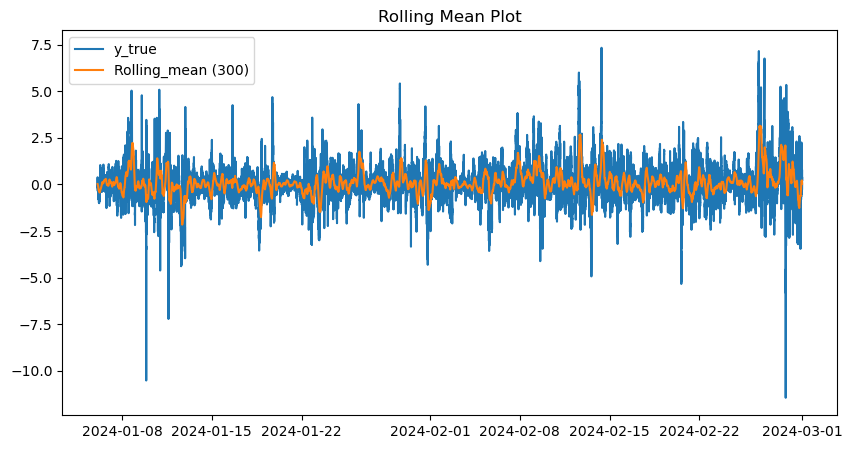

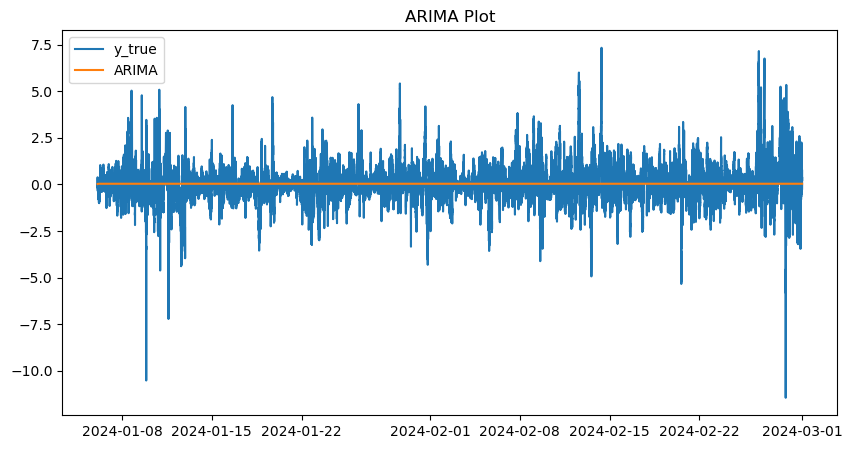

In [16]:
# baseline models
df = pd.read_parquet(train_path)
df = reduce_memory_use(df)
df = df.sort_index()

y = df['label']

split = int(len(y) * (1 - 0.15))
print(f'Training on {y.iloc[:split]}\nTesting on {y.iloc[split:]}')

rolling_mean = y.rolling(window=300, min_periods=60).mean().shift(1)
pred_roll = rolling_mean.iloc[split:].to_numpy()
if np.isnan(pred_roll).any():
    pred_roll = np.where(np.isnan(pred_roll), np.nanmean(rolling_mean.iloc[:split].to_numpy()), pred_roll)
score_roll = pearson_r(y.iloc[split:].to_numpy(), pred_roll)
print(f'Rolling Mean Pearson r score: {score_roll}')

arima_model = ARIMA(y.iloc[:split], order=(2, 1, 1))
pred_arima = arima_model.fit().forecast(steps=len(y.iloc[split:]))
score_arima = pearson_r(y.iloc[split:].to_numpy(), pred_arima)
print(f'ARIMA Pearson r score: {score_arima}')

plt.figure(figsize=(10, 5))
plt.plot(y.iloc[split:].index, y.iloc[split:], label='y_true')
plt.plot(y.iloc[split:].index, pred_roll, label='Rolling_mean (300)')
plt.title('Rolling Mean Plot')
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(y.iloc[split:].index, y.iloc[split:], label='y_true')
plt.plot(y.iloc[split:].index, pred_arima, label='ARIMA')
plt.title('ARIMA Plot')
plt.legend()
plt.show()

In [17]:
df.describe()

/opt/anaconda3/envs/luci/lib/python3.11/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/opt/anaconda3/envs/luci/lib/python3.11/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/opt/anaconda3/envs/luci/lib/python3.11/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/opt/anaconda3/envs/luci/lib/python3.11/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/opt/anaconda3/envs/luci/lib/python3.11/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/opt/anaconda3/envs/luci/lib/python3.11/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = s

,bid_qty,ask_qty,buy_qty,sell_qty,volume,X1,X2,X3,X4,X5,...,X882,X883,X884,X885,X886,X887,X888,X889,X890,label
count,525887.000000,525887.000000,525887.000000,525887.000000,525887.000000,525887.000000,525887.000000,525887.000000,525887.000000,525887.000000,...,525887.000000,525887.000000,525887.000000,525887.000000,525887.000000,525887.000000,525887.000000,525887.000000,525887.000000,525887.000000
mean,9.968003,10.174168,131.726678,132.673935,264.400622,-0.006026,-0.000243,-0.000353,-0.000425,-0.000263,...,1.959330,1.954978,0.498112,0.498062,0.497997,0.497872,0.497525,0.497372,0.995394,0.036126
std,15.642939,15.888200,307.267251,309.757446,588.618746,0.538292,0.613661,0.771651,0.857017,0.464656,...,0.844651,0.598208,0.713874,0.699725,0.685849,0.667574,0.615314,0.546406,0.850464,1.009775
min,0.001000,0.001000,0.000000,0.000000,0.000000,-2.787539,-5.861927,-6.125439,-6.093792,-2.855040,...,0.433416,0.686524,0.000004,0.000006,0.000009,0.000024,0.003903,0.015654,0.092913,-24.416615
25%,2.634000,2.678000,26.407000,27.021000,60.688500,-0.370635,-0.314135,-0.441536,-0.521693,-0.295502,...,1.367222,1.521202,0.000162,0.000193,0.000241,0.000997,0.033156,0.066908,0.244373,-0.381585
50%,6.415000,6.538000,57.015000,58.047001,120.799000,-0.015991,-0.001713,-0.003010,-0.003948,-0.002545,...,1.831805,1.882957,0.000634,0.001036,0.004593,0.039178,0.127865,0.161757,0.634448,0.016262
75%,13.085000,13.330000,127.639000,129.110001,256.733500,0.349104,0.310181,0.431960,0.507830,0.287728,...,2.369648,2.274296,1.473225,1.472025,1.442417,1.380184,1.120480,0.999344,1.701838,0.434135
max,1114.932007,1352.964966,17614.400000,17686.234375,28701.419000,2.972741,6.151366,6.488532,6.394355,3.184776,...,6.881902,4.745380,1.584315,1.584315,1.584315,1.584315,1.583862,1.557910,2.769604,20.740271


In [18]:
# data cleaning training and pipeline
df = pd.read_parquet(train_path)
df_test = pd.read_parquet(test_path)
df = reduce_memory_use(df)
df_test = reduce_memory_use(df_test)
df = df.sort_index()
df = df.sort_index() if isinstance(df.index, pd.DatetimeIndex) else df.sort_values('timestamp')
df = add_features(df)
df_test = add_features(df_test)

for i in (df, df_test):
    i.replace([np.inf, -np.inf], np.nan, inplace=True)

features = [i for i in (['bid_qty', 'ask_qty', 'buy_qty', 'sell_qty', 'volume',
                         'order_imbalance', 'trade_imbalance', 'buy_sell_ratio_log',
                         'volume_ratio', 'participation'] + 
                         [x for x in df.columns if x.startswith('X')]) if i in df.columns]
feature_list = []
for f in features:
    if not df[f].isna().all() and not (df[f].count() > 0 and df[f].nunique(dropna=True) == 1):
        feature_list.append(f)

X_df = df[feature_list]
y = df['label'].astype(np.float32).values
X_test_df = X_test = df_test[X_df.columns]

pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])

ridge_pipe = Pipeline([('pipe', pipe), ('model', Ridge(alpha=15.0, random_state=42, max_iter=3000))])
lasso_pipe = Pipeline([('pipe', pipe), ('model', Lasso(alpha=0.01, random_state=42, max_iter=3000))])
elastic_pipe = Pipeline([('pipe', pipe), ('model', ElasticNet(alpha=0.01, l1_ratio=0.6, random_state=42, max_iter=3000))])

grid = {'Ridge': (ridge_pipe, {'model__alpha': [15.0]}),
        'Lasso': (lasso_pipe, {'model__alpha': [0.01]}),
        'ElasticNet': (elastic_pipe, {'model__alpha': [0.01], 'model__l1_ratio':[0.6]})}

cv_split = TimeSeriesSplit(n_splits=4)

def cv_fit(name, pipe, grid, x, y):
    search = GridSearchCV(pipe, grid, scoring=correlation_scorer, cv=cv_split, refit=True, n_jobs=os.cpu_count(), verbose=0)
    search.fit(x, y)
    top = search.best_estimator_
    pred = np.full(len(x), np.nan, dtype=np.float32)
    scores = []
    for e, i in cv_split.split(x):
        top.fit(x.iloc[e], y[e])
        pred_temp = top.predict(x.iloc[i])
        pred[i] = pred_temp
        scores.append(pearson_r(y[i], pred_temp))
    print(f'{name}: Pearson r mean on out of fold prediction: {np.nanmean(scores)}')
    return top, pred

ridge_top, ridge_pred = cv_fit('Ridge', *grid['Ridge'], X_df, y)
lasso_top, lasso_pred = cv_fit('Lasso', *grid['Lasso'], X_df, y)
elastic_top, elastic_pred = cv_fit('ElasticNet', *grid['ElasticNet'], X_df, y)

/var/folders/xf/h4xr85dn3d1d6gxjpf_rl78m0000gn/T/ipykernel_35920/3955399765.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['order_imbalance'] = (bid - ask) / (bid + ask + norm)
/var/folders/xf/h4xr85dn3d1d6gxjpf_rl78m0000gn/T/ipykernel_35920/3955399765.py:21: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['trade_imbalance'] = (buy - sell) / (buy + sell + norm)
/var/folders/xf/h4xr85dn3d1d6gxjpf_rl78m0000gn/T/ipykernel_35920/3955399765.py:22: PerformanceWarning: DataFrame is highly fragmented.  This is usually the resu

Ridge: Pearson r mean on out of fold prediction: 0.0445600490748715
Lasso: Pearson r mean on out of fold prediction: 0.1288444734950236
ElasticNet: Pearson r mean on out of fold prediction: 0.12090592855055107


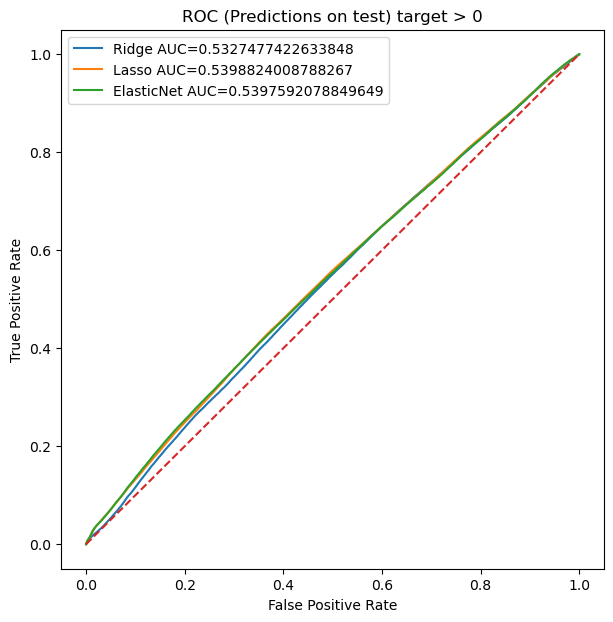

In [19]:
# roc scores and auc
plt.figure(figsize=(7, 7))
for name, pred in {'Ridge': ridge_pred, 'Lasso': lasso_pred, 'ElasticNet': elastic_pred}.items():
    mask = ~np.isnan(pred)
    boolean = (y[mask] > 0)
    false_pos_rate, true_pos_rate, _ = roc_curve(boolean, pred[mask])
    plt.plot(false_pos_rate, true_pos_rate, label=f'{name} AUC={auc(false_pos_rate,true_pos_rate)}')
plt.plot([0,1], [0,1], '--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC (Predictions on test) target > 0')
plt.legend()
plt.show()

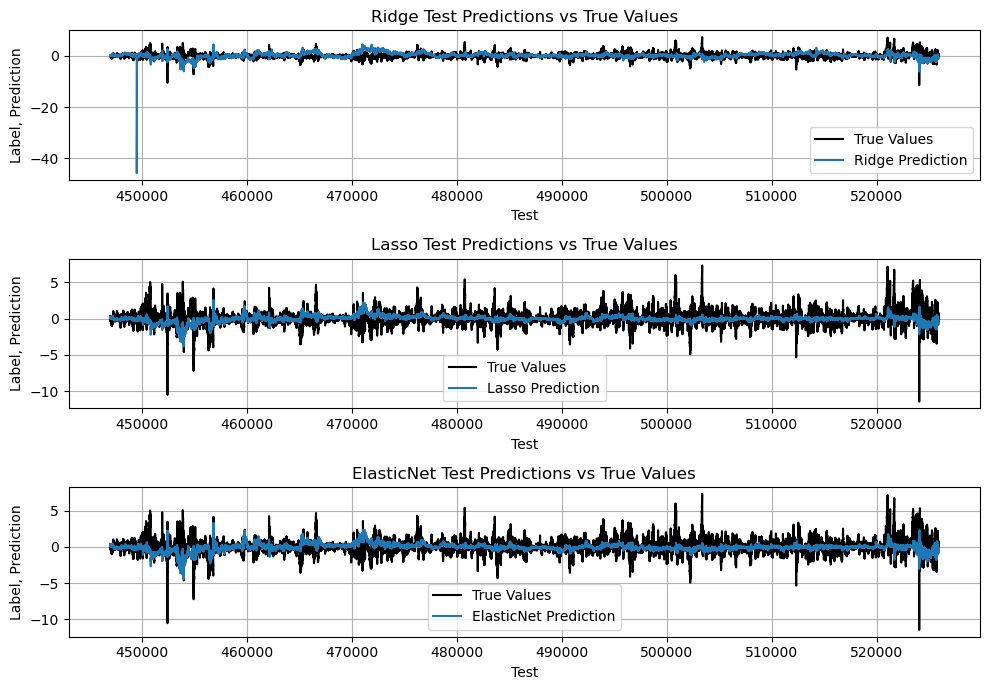

In [ ]:
# test on test data that we held out
holdout_test = int(len(y) * (0.85))
start = np.arange(holdout_test, len(y))
plt.figure(figsize=(10, 7))
for i, (name, pred) in enumerate({'Ridge': ridge_pred,
                                 'Lasso': lasso_pred,
                                 'ElasticNet': elastic_pred}.items(), start=1):
    plt.subplot(3, 1, i)
    plt.plot(start, y[start], label = 'True Values', color='black')
    plt.plot(start, pred[start], label=f'{name} Prediction')
    plt.title(f'{name} Test Predictions vs True Values')
    plt.xlabel('Test')
    plt.ylabel('Label, Prediction')
    plt.legend()
    plt.tight_layout()
    plt.grid(True)
plt.show()